In [1]:
import sys

print("Python usado:")
print(sys.executable)

Python usado:
c:\Users\sarah\OneDrive\Desktop\sistema_riesgo_cardiaco\.venv\Scripts\python.exe


In [2]:
import pandas as pd

df = pd.read_csv("../datos/heart_model.csv")

print("Dimensiones del dataset:", df.shape)
print("\nPrimeras filas:")
display(df.head())

print("\nTipos de datos:")
print(df.dtypes)

Dimensiones del dataset: (297, 14)

Primeras filas:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Tipos de datos:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object


In [3]:
# Distribución de la variable objetivo
print("Distribución de target:")
print(df["target"].value_counts().sort_index())

print("\nPorcentajes:")
print(df["target"].value_counts(normalize=True).sort_index() * 100)

Distribución de target:
target
0    160
1    137
Name: count, dtype: int64

Porcentajes:
target
0    53.872054
1    46.127946
Name: proportion, dtype: float64


In [4]:
# Valores faltantes
print("Valores faltantes por variable:")
print(df.isnull().sum())

Valores faltantes por variable:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [5]:
# Estadísticas descriptivas
print("Estadísticas descriptivas:")
display(df.describe().T)

Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
age,297.0,54.542088,9.049736,29.0,48.0,56.0,61.0,77.0
sex,297.0,0.676768,0.468500,0.0,0.0,1.0,1.0,1.0
cp,297.0,3.158249,0.964859,1.0,3.0,3.0,4.0,4.0
trestbps,297.0,131.693603,17.762806,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.350168,51.997583,126.0,211.0,243.0,276.0,564.0
fbs,297.0,0.144781,0.352474,0.0,0.0,0.0,0.0,1.0
restecg,297.0,0.996633,0.994914,0.0,0.0,1.0,2.0,2.0
thalach,297.0,149.599327,22.941562,71.0,133.0,153.0,166.0,202.0
exang,297.0,0.326599,0.469761,0.0,0.0,0.0,1.0,1.0
oldpeak,297.0,1.055556,1.166123,0.0,0.0,0.8,1.6,6.2


In [6]:
# Promedios de las variables según target
print("Promedios según target:")
display(df.groupby("target").mean().T)

Promedios según target:


target,0,1
age,52.64375,56.759124
sex,0.55625,0.817518
cp,2.79375,3.583942
trestbps,129.17500,134.635036
chol,243.49375,251.854015
fbs,0.14375,0.145985
restecg,0.84375,1.175182
thalach,158.58125,139.109489
exang,0.14375,0.540146
oldpeak,0.59875,1.589051


<Figure size 800x500 with 0 Axes>

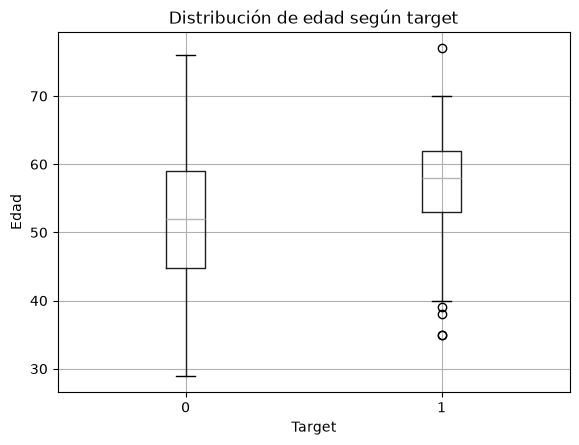

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df.boxplot(column="age", by="target")

plt.title("Distribución de edad según target")
plt.suptitle("")
plt.xlabel("Target")
plt.ylabel("Edad")
plt.show()

<Figure size 800x500 with 0 Axes>

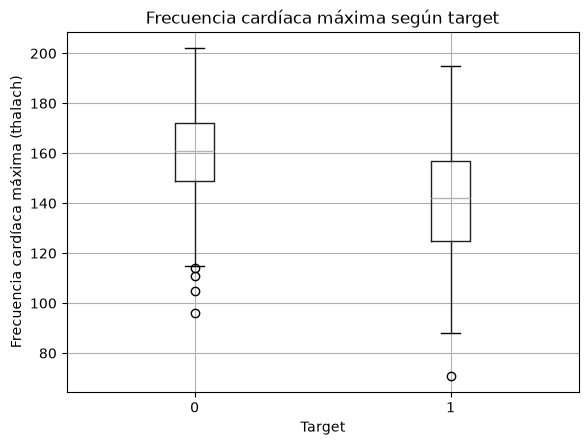

In [8]:
# Frecuencia cardíaca máxima según target

plt.figure(figsize=(8, 5))

df.boxplot(column="thalach", by="target")

plt.title("Frecuencia cardíaca máxima según target")
plt.suptitle("")
plt.xlabel("Target")
plt.ylabel("Frecuencia cardíaca máxima (thalach)")
plt.show()

In [9]:
# Distribución de oldpeak según target
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="oldpeak")

plt.title("Depresión ST (oldpeak) según target")
plt.xlabel("Target")
plt.ylabel("Oldpeak")

plt.show()

NameError: name 'sns' is not defined

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

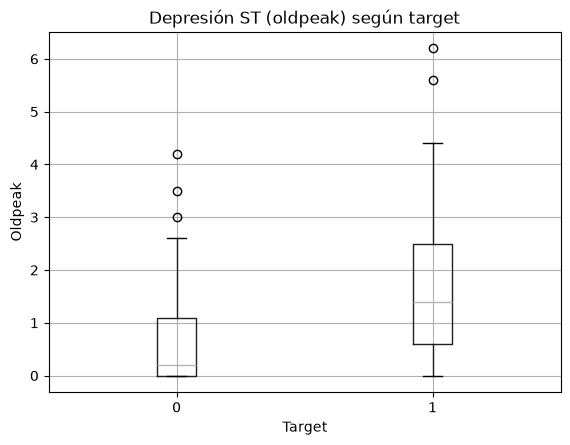

In [10]:
# Distribución de oldpeak según target
plt.figure(figsize=(8, 5))

df.boxplot(column="oldpeak", by="target")

plt.title("Depresión ST (oldpeak) según target")
plt.suptitle("")
plt.xlabel("Target")
plt.ylabel("Oldpeak")

plt.show()

In [11]:
# Distribución de variables categóricas según target

variables_categoricas = ["sex", "cp", "exang", "ca", "thal"]

for variable in variables_categoricas:
    print(f"\nDistribución de {variable} según target:")
    print(pd.crosstab(df[variable], df["target"], normalize="index") * 100)


Distribución de sex según target:
target          0          1
sex                         
0.0     73.958333  26.041667
1.0     44.278607  55.721393

Distribución de cp según target:
target          0          1
cp                          
1.0     69.565217  30.434783
2.0     81.632653  18.367347
3.0     78.313253  21.686747
4.0     27.464789  72.535211

Distribución de exang según target:
target         0         1
exang                     
0.0     68.50000  31.50000
1.0     23.71134  76.28866

Distribución de ca según target:
target          0          1
ca                          
0.0     74.137931  25.862069
1.0     32.307692  67.692308
2.0     18.421053  81.578947
3.0     15.000000  85.000000

Distribución de thal según target:
target          0          1
thal                        
3.0     77.439024  22.560976
6.0     33.333333  66.666667
7.0     23.478261  76.521739


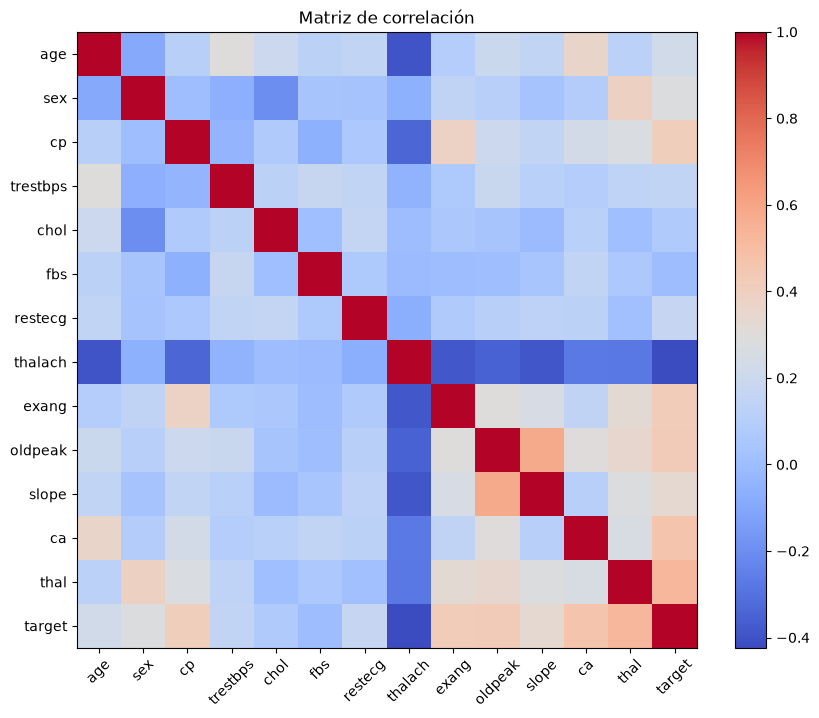

In [12]:
# Matriz de correlación
plt.figure(figsize=(10, 8))

correlacion = df.corr(numeric_only=True)

plt.imshow(correlacion, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(range(len(correlacion.columns)), correlacion.columns, rotation=45)
plt.yticks(range(len(correlacion.columns)), correlacion.columns)

plt.title("Matriz de correlación")

plt.show()

In [13]:
# Correlación de cada variable con target
correlacion_target = df.corr(numeric_only=True)["target"].sort_values(ascending=False)

print("Correlación de las variables con target:")
display(correlacion_target)

Correlación de las variables con target:


target      1.000000
thal        0.526640
ca          0.463189
oldpeak     0.424052
exang       0.421355
cp          0.408945
slope       0.333049
sex         0.278467
age         0.227075
restecg     0.166343
trestbps    0.153490
chol        0.080285
fbs         0.003167
thalach    -0.423817
Name: target, dtype: float64

In [14]:
# Separar variables predictoras (X) y variable objetivo (y)

X = df.drop("target", axis=1)
y = df["target"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (297, 13)
Dimensiones de y: (297,)


In [15]:
# Dividir los datos en entrenamiento y prueba

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (237, 13)
Datos de prueba: (60, 13)


In [16]:
# Escalar las variables predictoras

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dimensiones de X_train_scaled:", X_train_scaled.shape)
print("Dimensiones de X_test_scaled:", X_test_scaled.shape)

Dimensiones de X_train_scaled: (237, 13)
Dimensiones de X_test_scaled: (60, 13)


In [17]:
# Entrenar el primer modelo: Regresión Logística

from sklearn.linear_model import LogisticRegression

modelo_logistico = LogisticRegression(random_state=42)

modelo_logistico.fit(X_train_scaled, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [18]:
# Generar predicciones sobre los datos de prueba

y_pred = modelo_logistico.predict(X_test_scaled)

print("Primeras predicciones:")
print(y_pred[:20])

Primeras predicciones:
[0 0 0 0 1 0 1 0 0 0 1 0 1 1 1 0 1 0 1 1]


In [19]:
# Evaluar las predicciones del modelo

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy del modelo:", accuracy)

Accuracy del modelo: 0.8333333333333334


In [20]:
# Evaluación completa del modelo

from sklearn.metrics import classification_report

print("Reporte de clasificación:")
print(classification_report(y_test, y_pred))

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85        32
           1       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60



Matriz de confusión:
[[28  4]
 [ 6 22]]


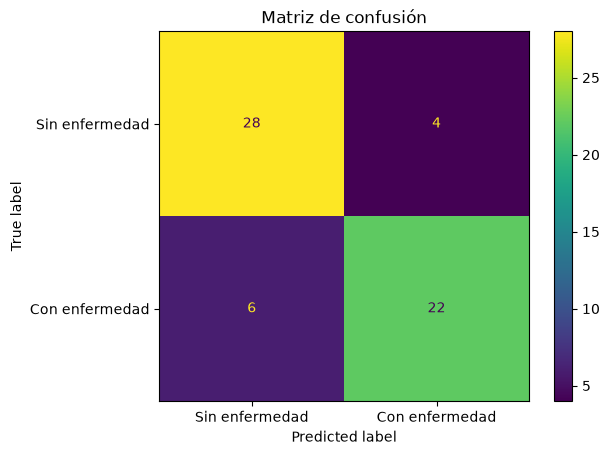

In [21]:
# Matriz de confusión

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Matriz de confusión:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sin enfermedad", "Con enfermedad"]
)

disp.plot()
plt.title("Matriz de confusión")
plt.show()

AUC del modelo: 0.9497767857142857


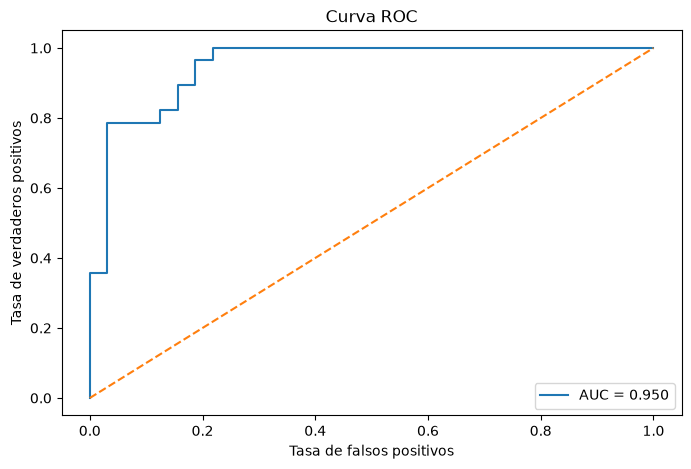

In [22]:
# Curva ROC y AUC

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = modelo_logistico.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

print("AUC del modelo:", auc)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("Curva ROC")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.show()

In [23]:
# Guardar el modelo entrenado

import joblib

joblib.dump(modelo_logistico, "../modelos/modelo_logistico.pkl")

print("Modelo guardado correctamente.")

Modelo guardado correctamente.


In [24]:
# Entrenamiento de Random Forest

from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

modelo_rf.fit(X_train_scaled, y_train)

print("Random Forest entrenado correctamente.")

Random Forest entrenado correctamente.


In [25]:
# Predicciones de Random Forest

y_pred_rf = modelo_rf.predict(X_test_scaled)

print("Primeras predicciones de Random Forest:")
print(y_pred_rf[:20])

Primeras predicciones de Random Forest:
[0 0 0 1 0 0 1 0 0 0 1 0 1 1 1 1 1 0 1 1]


In [26]:
from sklearn.metrics import accuracy_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Accuracy del Random Forest:", accuracy_rf)

Accuracy del Random Forest: 0.8666666666666667


In [27]:
from sklearn.metrics import classification_report

print("Reporte de clasificación - Random Forest:")
print(classification_report(y_test, y_pred_rf))

Reporte de clasificación - Random Forest:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88        32
           1       0.88      0.82      0.85        28

    accuracy                           0.87        60
   macro avg       0.87      0.86      0.87        60
weighted avg       0.87      0.87      0.87        60



Matriz de confusión - Random Forest:
[[29  3]
 [ 5 23]]


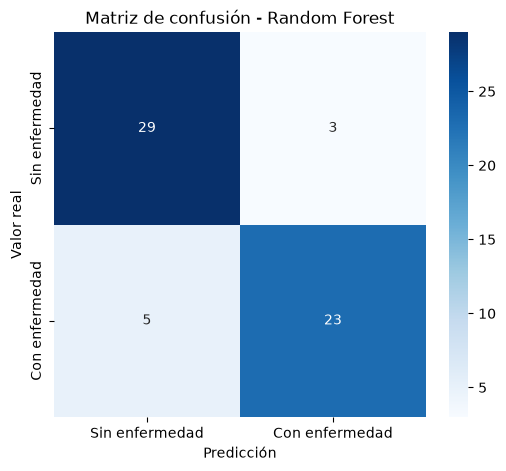

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Matriz de confusión - Random Forest:")
print(cm_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Sin enfermedad", "Con enfermedad"],
    yticklabels=["Sin enfermedad", "Con enfermedad"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Random Forest")
plt.show()

AUC del Random Forest: 0.94140625


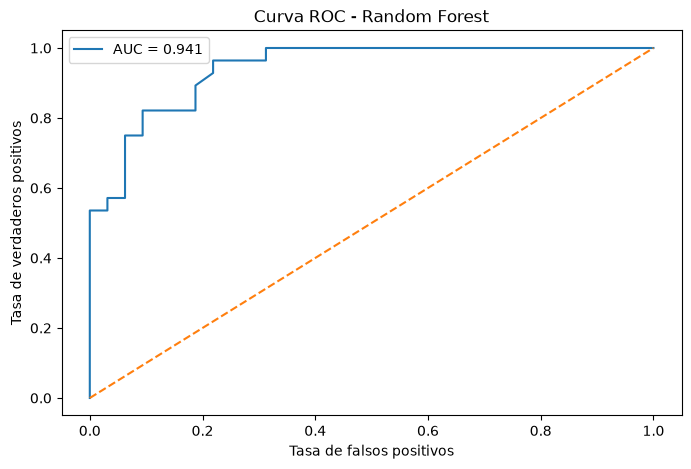

In [29]:
from sklearn.metrics import roc_curve, roc_auc_score

# Probabilidades de la clase positiva
y_prob_rf = modelo_rf.predict_proba(X_test_scaled)[:, 1]

# Calcular curva ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Calcular AUC
auc_rf = roc_auc_score(y_test, y_prob_rf)

print("AUC del Random Forest:", auc_rf)

plt.figure(figsize=(8, 5))
plt.plot(fpr_rf, tpr_rf, label=f"AUC = {auc_rf:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC - Random Forest")
plt.legend()
plt.show()

In [30]:
# Comparación de modelos

comparacion = pd.DataFrame({
    "Modelo": ["Regresión Logística", "Random Forest"],
    "Accuracy": [accuracy, accuracy_rf],
    "F1-score": [
        classification_report(y_test, y_pred, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, y_pred_rf, output_dict=True)["1"]["f1-score"]
    ],
    "AUC": [auc, auc_rf]
})

display(comparacion)

,Modelo,Accuracy,F1-score,AUC
0,Regresión Logística,0.833333,0.814815,0.949777
1,Random Forest,0.866667,0.851852,0.941406


In [31]:
from sklearn.model_selection import GridSearchCV

parametros_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    parametros_rf,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_rf.fit(X_train_scaled, y_train)

print("Mejores parámetros:")
print(grid_rf.best_params_)

print("Mejor F1 de validación cruzada:")
print(grid_rf.best_score_)

Mejores parámetros:
{'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Mejor F1 de validación cruzada:
0.8108791606262894


In [32]:
# Random Forest optimizado

modelo_rf_optimizado = grid_rf.best_estimator_

# Predicciones sobre el conjunto de prueba
y_pred_rf_opt = modelo_rf_optimizado.predict(X_test_scaled)

print("Random Forest optimizado listo.")

Random Forest optimizado listo.


In [33]:
from sklearn.metrics import accuracy_score

accuracy_rf_opt = accuracy_score(y_test, y_pred_rf_opt)

print("Accuracy del Random Forest optimizado:", accuracy_rf_opt)

Accuracy del Random Forest optimizado: 0.8166666666666667


In [34]:
from sklearn.metrics import classification_report

print("Reporte de clasificación - Random Forest optimizado:")
print(classification_report(y_test, y_pred_rf_opt))

Reporte de clasificación - Random Forest optimizado:
              precision    recall  f1-score   support

           0       0.78      0.91      0.84        32
           1       0.87      0.71      0.78        28

    accuracy                           0.82        60
   macro avg       0.83      0.81      0.81        60
weighted avg       0.82      0.82      0.81        60



In [35]:
# Selección del mejor modelo

mejor_modelo = modelo_rf
nombre_mejor_modelo = "Random Forest"

print("Modelo seleccionado:", nombre_mejor_modelo)
print("Accuracy:", accuracy_rf)

Modelo seleccionado: Random Forest
Accuracy: 0.8666666666666667


In [36]:
# Guardar el modelo definitivo

import joblib

joblib.dump(mejor_modelo, "../modelos/modelo_final.pkl")

print("Modelo definitivo guardado correctamente.")

Modelo definitivo guardado correctamente.


In [37]:
# Preparar el escalado para un nuevo paciente

from sklearn.preprocessing import StandardScaler

# Crear el paciente de ejemplo
nuevo_paciente = pd.DataFrame([{
    "age": 55,
    "sex": 1,
    "cp": 2,
    "trestbps": 140,
    "chol": 250,
    "fbs": 0,
    "restecg": 1,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.5,
    "slope": 1,
    "ca": 0,
    "thal": 2
}])

# Escalador utilizado durante el entrenamiento
scaler_nuevo = StandardScaler()
scaler_nuevo.fit(X_train)

# Escalar los datos del nuevo paciente
nuevo_paciente_scaled = scaler_nuevo.transform(nuevo_paciente)

# Realizar predicción
prediccion = modelo_final.predict(nuevo_paciente_scaled)

print("Predicción:", prediccion[0])

if prediccion[0] == 1:
    print("Resultado: Con enfermedad")
else:
    print("Resultado: Sin enfermedad")

NameError: name 'modelo_final' is not defined

In [38]:
# Prueba de predicción para un nuevo paciente

import pandas as pd
import joblib
from sklearn.preprocessing import StandardScaler

# Cargar el modelo definitivo
modelo_final = joblib.load("../modelos/modelo_final.pkl")

# Datos de ejemplo de un paciente
nuevo_paciente = pd.DataFrame([{
    "age": 55,
    "sex": 1,
    "cp": 2,
    "trestbps": 140,
    "chol": 250,
    "fbs": 0,
    "restecg": 1,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.5,
    "slope": 1,
    "ca": 0,
    "thal": 2
}])

# Crear el mismo tipo de escalado utilizado durante el entrenamiento
scaler_nuevo = StandardScaler()
scaler_nuevo.fit(X_train)

# Escalar los datos del nuevo paciente
nuevo_paciente_scaled = scaler_nuevo.transform(nuevo_paciente)

# Realizar predicción
prediccion = modelo_final.predict(nuevo_paciente_scaled)

print("Predicción:", prediccion[0])

if prediccion[0] == 1:
    print("Resultado: Con enfermedad")
else:
    print("Resultado: Sin enfermedad")

Predicción: 0
Resultado: Sin enfermedad


In [39]:
# Guardar el escalador utilizado por el modelo

import joblib

joblib.dump(scaler_nuevo, "../modelos/scaler.pkl")

print("Escalador guardado correctamente.")

Escalador guardado correctamente.
